# DeepFER – Phase 1: Dataset Exploration & Quality Audit

**Environment:** Google Colab  
**Input:** `Face Emotion Recognition Dataset (1).zip`  
**Goal:** inspect the seven-class facial-expression dataset, identify archive duplication, class imbalance, corrupt files, duplicate images and train/validation leakage.

> Run cells from top to bottom. The notebook does not train a model. It produces a reproducible audit and exports reports.

## 1. Runtime setup

In Colab, select **Runtime → Change runtime type**. A GPU is not required for this phase; CPU is sufficient.

In [ ]:
!pip -q install pillow pandas numpy matplotlib seaborn scikit-learn

## 2. Upload the dataset ZIP

Upload `Face Emotion Recognition Dataset (1).zip` when prompted. Alternatively, mount Google Drive and set `ZIP_PATH` manually.

In [ ]:
from google.colab import files
uploaded = files.upload()

zip_candidates = [name for name in uploaded if name.lower().endswith(".zip")]
if not zip_candidates:
    raise FileNotFoundError("Please upload a .zip dataset file.")
ZIP_PATH = zip_candidates[0]
print("Using:", ZIP_PATH)

Saving Face Emotion Recognition Dataset (1).zip to Face Emotion Recognition Dataset (1).zip
Using: Face Emotion Recognition Dataset (1).zip


## 3. Extract and inspect archive structure

The supplied archive was found to contain both `images/` and a nested `images/images/` copy. This notebook detects that condition and chooses one canonical copy so the same images are not counted twice.

In [ ]:
from pathlib import Path
import zipfile, os

EXTRACT_DIR = Path("/content/deepfer_extracted")
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH) as zf:
    zf.extractall(EXTRACT_DIR)

print("Extraction complete:", EXTRACT_DIR)
for p in sorted(EXTRACT_DIR.rglob("*")):
    if p.is_dir() and len(p.relative_to(EXTRACT_DIR).parts) <= 3:
        print(p.relative_to(EXTRACT_DIR))

Extraction complete: /content/deepfer_extracted
images
images/images
images/images/train
images/images/validation
images/train
images/train/angry
images/train/disgust
images/train/fear
images/train/happy
images/train/neutral
images/train/sad
images/train/surprise
images/validation
images/validation/angry
images/validation/disgust
images/validation/fear
images/validation/happy
images/validation/neutral
images/validation/sad
images/validation/surprise


## 4. Build a canonical image manifest

Expected labels: `angry`, `disgust`, `fear`, `happy`, `neutral`, `sad`, `surprise`.

The archive may have an extra outer folder. The code finds image files by their parent emotion folder and the nearest `train`, `validation`, or `test` ancestor.

In [ ]:
import pandas as pd
from collections import Counter
from PIL import Image
import hashlib

CLASSES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLITS = {"train", "validation", "test"}

all_files = [p for p in EXTRACT_DIR.rglob("*") if p.is_file() and p.suffix.lower() in VALID_EXT]

# Find mirrored directory copies by relative suffix below the split folder.
candidates = []
for p in all_files:
    parts = p.parts
    split_idx = next((i for i, part in enumerate(parts) if part.lower() in SPLITS), None)
    if split_idx is None or split_idx + 1 >= len(parts):
        continue
    split = parts[split_idx].lower()
    label = parts[split_idx + 1].lower()
    if label not in CLASSES:
        continue
    candidates.append({"path": str(p), "split": split, "emotion": label,
                       "relative_image": "/".join(parts[split_idx+2:])})

# Keep one copy per split/class/relative image path.
manifest_df = pd.DataFrame(candidates)
if manifest_df.empty:
    raise ValueError("Could not detect split/class folders. Inspect the printed folder tree and adjust the archive layout.")

manifest_df = manifest_df.drop_duplicates(
    subset=["split", "emotion", "relative_image"], keep="first"
).reset_index(drop=True)

print("Canonical image files:", len(manifest_df))
display(manifest_df.head())

Canonical image files: 35887


,path,split,emotion,relative_image
0,/content/deepfer_extracted/images/images/valid...,validation,angry,25343.jpg
1,/content/deepfer_extracted/images/images/valid...,validation,angry,34474.jpg
2,/content/deepfer_extracted/images/images/valid...,validation,angry,14118.jpg
3,/content/deepfer_extracted/images/images/valid...,validation,angry,15654.jpg
4,/content/deepfer_extracted/images/images/valid...,validation,angry,15217.jpg


## 5. Validate images, record dimensions and compute SHA-256 hashes

Hashing detects byte-identical images. A duplicate hash does not necessarily mean the expression label is correct; duplicate images assigned to different labels need manual review.

In [ ]:
records, corrupt = [], []
for row in manifest_df.itertuples(index=False):
    path = Path(row.path)
    try:
        raw = path.read_bytes()
        digest = hashlib.sha256(raw).hexdigest()
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            width, height = im.size
            mode = im.mode
        records.append({
            "path": str(path), "split": row.split, "emotion": row.emotion,
            "width": width, "height": height, "mode": mode,
            "bytes": path.stat().st_size, "sha256": digest
        })
    except Exception as exc:
        corrupt.append({"path": str(path), "error": str(exc)})

audit_df = pd.DataFrame(records)
corrupt_df = pd.DataFrame(corrupt)
print("Valid images:", len(audit_df))
print("Corrupt images:", len(corrupt_df))
display(audit_df.head())

Valid images: 35887
Corrupt images: 0


,path,split,emotion,width,height,mode,bytes,sha256
0,/content/deepfer_extracted/images/images/valid...,validation,angry,48,48,L,1802,639b6358efd5719a259e7d522b429dc47077d10c9e02f1...
1,/content/deepfer_extracted/images/images/valid...,validation,angry,48,48,L,1582,2031dc4a48370dd49c7902829d4793b548e23d93d78814...
2,/content/deepfer_extracted/images/images/valid...,validation,angry,48,48,L,1731,8db16e586238af5a4280490ce70287a93a9839e3efe5ab...
3,/content/deepfer_extracted/images/images/valid...,validation,angry,48,48,L,1232,a56dc39c8554a4d9c99a2968218c9c85a9ab8cfacc9c31...
4,/content/deepfer_extracted/images/images/valid...,validation,angry,48,48,L,1684,9b609e8848ab01869618bf43446c23eb5b1075b8c9c223...


## 6. Class distribution and charts

emotion,angry,disgust,fear,happy,neutral,sad,surprise
split,,,,,,,
train,3993,436,4103,7164,4982,4938,3205
validation,960,111,1018,1825,1216,1139,797


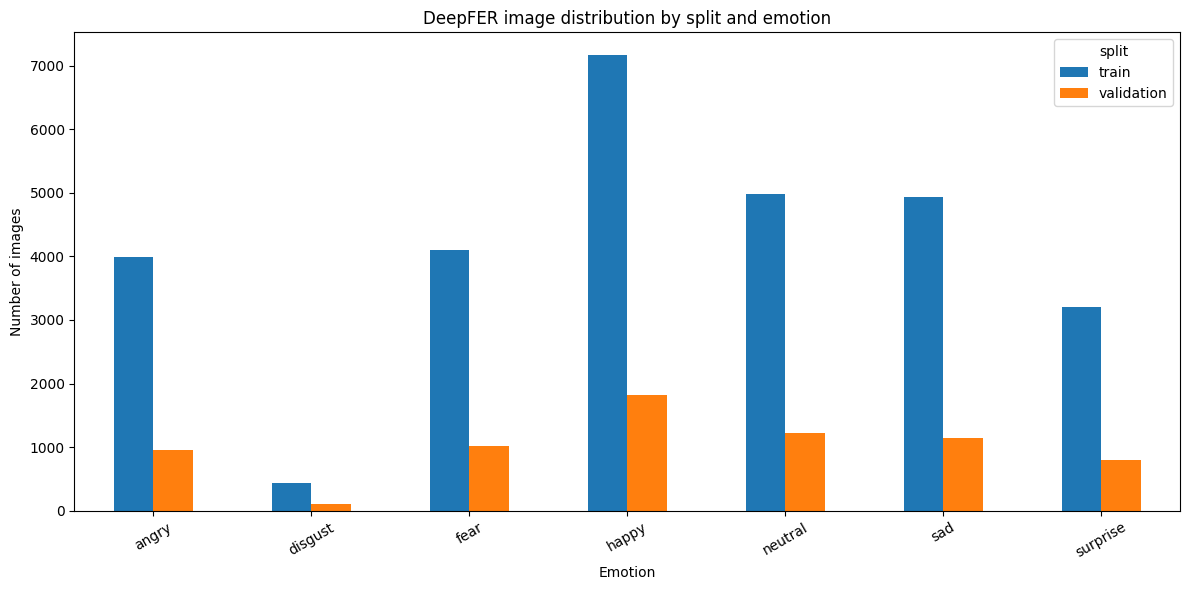

Largest/smallest training class ratio: 16.43


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

distribution = (audit_df.groupby(["split", "emotion"]).size()
                .unstack(fill_value=0).reindex(columns=CLASSES, fill_value=0))
display(distribution)

ax = distribution.T.plot(kind="bar", figsize=(12, 6))
ax.set_title("DeepFER image distribution by split and emotion")
ax.set_xlabel("Emotion")
ax.set_ylabel("Number of images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

train_counts = distribution.loc["train"] if "train" in distribution.index else pd.Series(dtype=int)
if len(train_counts):
    print("Largest/smallest training class ratio:",
          round(train_counts.max() / max(train_counts.min(), 1), 2))

## 7. Exact duplicates and split leakage

Two checks are reported separately:
- **Repeated files within the same split/class:** exact duplicate content appears more than once.
- **Cross-split duplicate hashes:** identical content appears in more than one split. These should be removed or grouped before model evaluation to avoid leakage.

Do not automatically delete records based only on a matching hash when labels conflict. Review the conflicting rows first.

In [ ]:
duplicate_rows = audit_df[audit_df.duplicated("sha256", keep=False)].sort_values("sha256")
duplicate_summary = (duplicate_rows.groupby("sha256")
                     .agg(copies=("path", "count"),
                          splits=("split", lambda x: ", ".join(sorted(set(x)))),
                          labels=("emotion", lambda x: ", ".join(sorted(set(x)))),
                          paths=("path", lambda x: " | ".join(x)))
                     .reset_index())

cross_split = duplicate_summary[
    duplicate_summary["splits"].str.contains(",")
]
conflicting_labels = duplicate_summary[
    duplicate_summary["labels"].str.contains(",")
]

print("Duplicate hash groups:", len(duplicate_summary))
print("Cross-split duplicate groups:", len(cross_split))
print("Groups with conflicting emotion labels:", len(conflicting_labels))
display(cross_split.head(20))
display(conflicting_labels.head(20))

Duplicate hash groups: 1516
Cross-split duplicate groups: 510
Groups with conflicting emotion labels: 57


,sha256,copies,splits,labels,paths
0,0007a9cdfcdc57487231d5ae31c543621cd95c2d366100...,2,"train, validation",surprise,/content/deepfer_extracted/images/images/valid...
1,001b4b1c0bc0355e3df9079191a4cdce678fa324ca5d8f...,3,"train, validation",surprise,/content/deepfer_extracted/images/images/valid...
4,00e3078e891ff7c88cffa7040b816b7a2ae4bb38a68e3f...,2,"train, validation",happy,/content/deepfer_extracted/images/images/train...
5,00e32203eb7b9c880c36df064e60cc19ad54c04a0f84ed...,3,"train, validation",surprise,/content/deepfer_extracted/images/images/train...
6,012196db4f177cfdc5aab61d4d2ccdf0aa3a420d3d09c8...,2,"train, validation",happy,/content/deepfer_extracted/images/images/valid...
11,0242799fea6a1e2d0de38d85d1afb3c6bf66dd8127fefe...,4,"train, validation",disgust,/content/deepfer_extracted/images/images/train...
12,025c6f20e9d8bcccc1c2e8cb4a26c9cfdc7632ccc4e9bf...,2,"train, validation",sad,/content/deepfer_extracted/images/images/valid...
17,02db770e4affa8782fb63a958c059b18bd7c4778a207ec...,2,"train, validation",surprise,/content/deepfer_extracted/images/images/valid...
19,03192becda10d0b3a8c9403beff8a1c991f6d45fce37e3...,3,"train, validation",fear,/content/deepfer_extracted/images/images/train...
20,0333b2194e4d33b0bd4ab8e07a10fe5ba2c16051ac9a52...,2,"train, validation",neutral,/content/deepfer_extracted/images/images/train...


,sha256,copies,splits,labels,paths
3,00567c7d6e6a818b519975b54a0bee17eab150fda91b95...,4,train,"disgust, fear",/content/deepfer_extracted/images/images/train...
55,099a979fe46008f0ca1a18010a24cacfb8409bbb744583...,2,"train, validation","fear, surprise",/content/deepfer_extracted/images/images/valid...
132,161a9457d5003123ed0de94a488f3a7f8cc7e1fe3c582c...,2,"train, validation","fear, neutral",/content/deepfer_extracted/images/images/valid...
190,200ac8bc39d686ea129cd47222c98de46b686793ebec18...,3,train,"fear, sad",/content/deepfer_extracted/images/images/train...
223,24e4ef151fe2569290f421101c336006c5c30dd671f5aa...,3,train,"angry, sad",/content/deepfer_extracted/images/images/train...
231,26bea2f8e1061751133a59b2ed374700e805e444c09a3b...,2,train,"happy, surprise",/content/deepfer_extracted/images/images/train...
299,31b92518b24475f181142b5da8c08bc83f679516f8b2c1...,2,train,"angry, fear",/content/deepfer_extracted/images/images/train...
315,3470c8a8b77d86a3fda906c7dca2d461fa5a4d6a18da82...,2,"train, validation","fear, surprise",/content/deepfer_extracted/images/images/train...
327,35a5e499e179360a5da52d92e3d48a55e76e26ba3dad53...,2,train,"angry, fear",/content/deepfer_extracted/images/images/train...
413,455f5a2c71ffe9a25cbb853a02aad0b7211a1f5c65bec5...,2,train,"happy, surprise",/content/deepfer_extracted/images/images/train...


## 8. Visualize example images

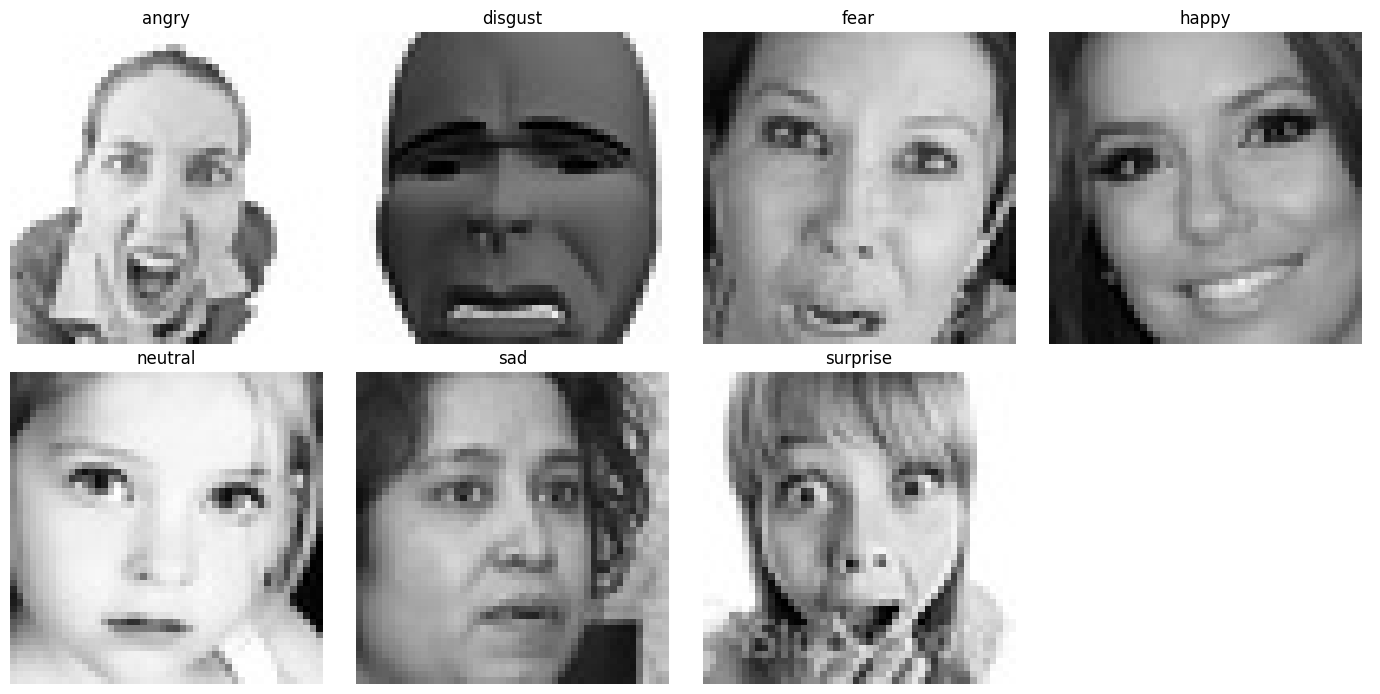

In [ ]:
import random
from PIL import Image

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, emotion in zip(axes.flat, CLASSES + [""]):
    if not emotion:
        ax.axis("off")
        continue
    samples = audit_df[audit_df.emotion == emotion]
    if samples.empty:
        ax.set_title(f"{emotion}: no images")
        ax.axis("off")
        continue
    sample = samples.sample(1, random_state=42).iloc[0]
    with Image.open(sample.path) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(emotion)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Export Phase 1 reports

The output folder contains a full image manifest, class distribution, duplicate report, corrupt-file report and a summary JSON.

In [ ]:
from pathlib import Path
import json

REPORT_DIR = Path("/content/DeepFER/reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

distribution.to_csv(REPORT_DIR / "class_distribution.csv")
audit_df.to_csv(REPORT_DIR / "image_manifest.csv", index=False)
duplicate_summary.to_csv(REPORT_DIR / "duplicate_hash_report.csv", index=False)
corrupt_df.to_csv(REPORT_DIR / "corrupt_images.csv", index=False)

summary = {
    "valid_images": int(len(audit_df)),
    "corrupt_images": int(len(corrupt_df)),
    "splits_found": sorted(audit_df.split.unique().tolist()),
    "classes_found": sorted(audit_df.emotion.unique().tolist()),
    "image_dimensions": audit_df.groupby(["width", "height"]).size().to_dict().__str__(),
    "duplicate_hash_groups": int(len(duplicate_summary)),
    "cross_split_duplicate_groups": int(len(cross_split)),
    "conflicting_label_duplicate_groups": int(len(conflicting_labels)),
    "class_distribution": {
        split: {label: int(value) for label, value in row.items()}
        for split, row in distribution.iterrows()
    }
}
with open(REPORT_DIR / "phase1_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Reports saved to:", REPORT_DIR)

Reports saved to: /content/DeepFER/reports


## 10. Download the report bundle

In [ ]:
import shutil
shutil.make_archive("/content/DeepFER_Phase1_Reports", "zip", REPORT_DIR)
from google.colab import files
files.download("/content/DeepFER_Phase1_Reports.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Phase 1 exit criteria

Before Phase 2, confirm:
1. All seven classes are present.
2. The split folders are understood.
3. Corrupt images are handled.
4. Exact duplicates and cross-split duplicates are reviewed.
5. The absence of a dedicated test split is addressed by creating a group-aware holdout from training data or another leakage-safe protocol.

**Do not train or report final test accuracy until duplicate leakage and the test split strategy have been resolved.**